# 🧩 Seleção de Templates WordPress: análise do gargalo de prazo

**Problema:** os sites da agência atrasavam, e a escolha do layout não seguia nenhum critério. Cada designer escolhia o template
que preferia entre 36 opções, o que gerava várias rodadas de aprovação e retrabalho no desenvolvimento.

**Objetivo:** usar o histórico de projetos (banco SQL) e o Google Analytics 4 para:
1. confirmar onde está o gargalo do prazo;
2. medir o desempenho de cada template por **nicho**, **tipo de site** e **tipo de página**;
3. ranquear os templates e escolher os **10 de maior desempenho**;
4. validar a proposta em um **teste piloto de 30 dias**, apresentado à gestão em um dashboard Excel;
5. medir o resultado depois da padronização (rollout).

| Período | Datas | O que aconteceu |
|---|---|---|
| Antes | jan/2023 a mar/2025 | escolha livre do layout |
| Transição | abr a mai/2025 | consolidação dos dados, diagnóstico e ranking |
| ↳ Teste piloto | 01 a 30/jun/2025 | A/B em 12 sites + 13 projetos Teste × Controle → dashboard Excel |
| Depois | jul/2025 a out/2026 | catálogo top 10 + fluxo documentado |

> ⚠️ Os dados são **simulados**, mas seguem a estrutura real de um banco de projetos e da exportação do GA4.

In [1]:
import sys, sqlite3
from pathlib import Path
import pandas as pd, numpy as np
from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import config as C, banco, analise as A, graficos as G
from ranking import PESOS

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
G.estilo()
proj, ga, etapas, templates, fato = A.carregar()
print(f"{len(proj)} projetos | {len(ga):,} linhas de GA4 | {len(templates)} templates | {proj.nicho.nunique()} nichos | {proj.tipo_site.nunique()} tipos de site")

362 projetos | 6,182 linhas de GA4 | 36 templates | 10 nichos | 6 tipos de site


## 1. Banco de dados centralizado
Modelo estrela com 5 dimensões e 3 fatos. As views em `sql/02_views.sql` integram projetos e GA4.

In [2]:
banco.ler("SELECT name, type FROM sqlite_master WHERE type IN ('table','view') ORDER BY type, name")

,name,type
0,dim_calendario,table
1,dim_clientes,table
2,dim_nichos,table
3,dim_templates,table
4,dim_tipos_site,table
5,fato_etapas,table
6,fato_ga4_paginas,table
7,fato_projetos,table
8,fato_teste_ab_ga4,table
9,vw_antes_depois,view


In [3]:
banco.ler("SELECT * FROM vw_projetos_desempenho LIMIT 5")

,projeto_id,periodo,nicho,tipo_site,template_id,nome_template,tema_base,page_builder,no_catalogo_padrao,data_inicio,data_entrega,dias_entrega,prazo_planejado_dias,no_prazo,rodadas_retrabalho,sessoes,conversoes,taxa_conversao
0,PRJ-0001,Antes,Saúde e Clínicas,Loja Virtual (WooCommerce),WP-29,Flatsome Prime Restaurantes,Flatsome,UX Builder,Sim,2023-01-05,2023-03-08,62,60,0,5,7394,165,0.02232
1,PRJ-0002,Antes,Imobiliárias,Landing Page,WP-17,Blocksy Minimal Moda,Blocksy,Gutenberg,Não,2023-01-10,2023-02-10,31,20,0,1,5312,185,0.03483
2,PRJ-0003,Antes,Academias e Fitness,Landing Page,WP-18,Neve Prime Contabilidade,Neve,Gutenberg,Não,2023-01-16,2023-02-23,38,20,0,1,2534,95,0.03749
3,PRJ-0004,Antes,Contabilidade,Blog / Portal,WP-09,OceanWP Classic Educação,OceanWP,Elementor,Não,2023-01-22,2023-03-01,38,35,0,1,2156,23,0.01067
4,PRJ-0005,Antes,Moda e Varejo,Portfólio,WP-09,OceanWP Classic Educação,OceanWP,Elementor,Não,2023-01-28,2023-03-05,36,32,0,2,5737,97,0.01691


## 2. Diagnóstico: onde está o gargalo?

In [4]:
garg = A.gargalo(etapas)
garg

,dias_antes,dias_depois,cv_antes,reducao_dias,pct_da_reducao_total
etapa,,,,,
Briefing,3.426,3.336,0.282,0.090,0.007
Escolha de layout,6.564,1.701,0.649,4.863,0.367
Design e aprovação,8.718,5.883,0.434,2.835,0.214
Desenvolvimento,14.015,9.912,0.525,4.103,0.310
Conteúdo,5.938,5.409,0.533,0.530,0.040
QA e ajustes,5.138,4.307,0.223,0.832,0.063
Publicação,1.000,1.000,0.000,0.000,0.000


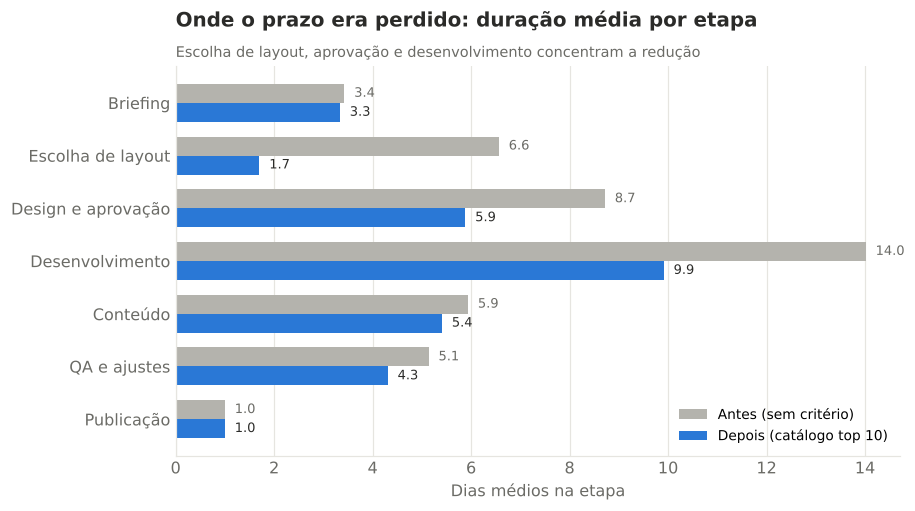

In [5]:
G.gargalo_etapas(garg);

**Leitura (período Antes):**
- *Escolha de layout* e *Design e aprovação* somavam **15,3 dias**, cerca de 34% do ciclo, sem gerar nada de código.
- A escolha de layout tinha a **maior variabilidade** de todas as etapas (coeficiente de variação na tabela), o que tornava o prazo imprevisível.
- O desenvolvimento também variava conforme o template: temas pesados (Avada/WPBakery, Divi) levavam mais tempo e geravam mais retrabalho.

In [6]:
cs = banco.consultas()
pd.read_sql_query(cs["Q3. Variabilidade do prazo por template no período ANTES (o sintoma)"], sqlite3.connect(C.DB))

,template_id,nome_template,page_builder,projetos,dias_medios,min_dias,max_dias,retrabalho_medio
0,WP-35,Flatsome Prime Educação,UX Builder,7,60.7,37,90,1.29
1,WP-25,Astra Modern Imobiliárias,Elementor,5,58.6,48,73,1.40
2,WP-29,Flatsome Prime Restaurantes,UX Builder,6,55.8,41,76,2.50
3,WP-26,Flatsome Clean Tecnologia,UX Builder,6,53.0,46,62,1.33
4,WP-12,Avada Minimal Educação,WPBakery,8,48.6,39,57,1.50
5,WP-32,Flatsome Modern Advocacia,UX Builder,6,48.5,45,57,1.17
6,WP-10,Avada Classic Tecnologia,WPBakery,10,48.0,34,61,2.30
7,WP-27,Hello Elementor Corporate Contabilidade,Elementor,6,45.3,34,58,2.00
8,WP-02,OceanWP Modern Tecnologia,Elementor,8,43.0,34,55,1.50
9,WP-06,Neve Classic Moda,Gutenberg,7,42.7,21,60,1.71


## 3. Integração com o GA4: conversão por nicho e tipo de página
Como cada nicho e cada tipo de página tem uma taxa natural diferente, a comparação justa entre templates usa um **benchmark** (`vw_benchmark_conversao`).

In [7]:
banco.ler("SELECT * FROM vw_benchmark_conversao ORDER BY nicho, taxa_benchmark DESC").head(12)

,nicho,tipo_pagina,sessoes,conversoes,taxa_benchmark
0,Academias e Fitness,Checkout,193,31,0.16062
1,Academias e Fitness,Contato,3578,241,0.06736
2,Academias e Fitness,Landing Page,10157,432,0.04253
3,Academias e Fitness,Serviços,1849,51,0.02758
4,Academias e Fitness,Produto,3955,82,0.02073
5,Academias e Fitness,Portfólio,4468,63,0.01410
6,Academias e Fitness,Home,19178,181,0.00944
7,Academias e Fitness,Sobre,964,8,0.00830
8,Academias e Fitness,Categoria,2468,18,0.00729
9,Academias e Fitness,Post de Blog,3052,7,0.00229


## 4. Ranking dos templates (somente dados do período Antes)
Calcular o ranking só com o período anterior evita *vazamento de dados*: a decisão foi tomada com a informação que existia na época.

In [8]:
pd.Series(PESOS, name="peso").to_frame()

,peso
lift_conversao,0.40
tempo_relativo,0.30
retrabalho_medio,0.15
pct_no_prazo,0.15


In [9]:
rank, top = A.ranking_antes(fato, ga, templates)
cols = ["posicao", "template_id", "nome_template", "page_builder", "familia", "projetos",
        "lift_conversao", "tempo_relativo", "retrabalho_medio", "pct_no_prazo", "score"]
rank[cols].round(2).head(15)

,posicao,template_id,nome_template,page_builder,familia,projetos,lift_conversao,tempo_relativo,retrabalho_medio,pct_no_prazo,score
0,1,WP-32,Flatsome Modern Advocacia,UX Builder,WooCommerce,6,1.31,0.96,1.17,0.67,74.17
1,2,WP-22,Astra Clean Restaurantes,Elementor,Geral,8,1.07,0.77,0.25,0.12,71.06
2,3,WP-15,Neve Minimal Saúde,Gutenberg,Geral,8,1.03,0.86,0.62,0.50,64.52
3,4,WP-05,GeneratePress Clean Tecnologia,Gutenberg,Geral,7,1.33,1.04,1.29,0.14,60.06
4,5,WP-11,Blocksy Bold Beleza,Gutenberg,Geral,6,1.07,0.96,0.83,0.33,55.93
5,6,WP-27,Hello Elementor Corporate Contabilidade,Elementor,WooCommerce,6,0.80,0.81,2.00,1.00,52.33
6,7,WP-13,Kadence Corporate Tecnologia,Gutenberg,Geral,6,0.99,0.88,1.00,0.00,51.06
7,8,WP-08,Astra Corporate Saúde,Elementor,Geral,7,0.91,0.87,1.29,0.43,50.92
8,9,WP-29,Flatsome Prime Restaurantes,UX Builder,WooCommerce,6,1.21,1.04,2.50,0.50,50.23
9,10,WP-06,Neve Classic Moda,Gutenberg,Geral,7,1.16,1.01,1.71,0.14,49.31


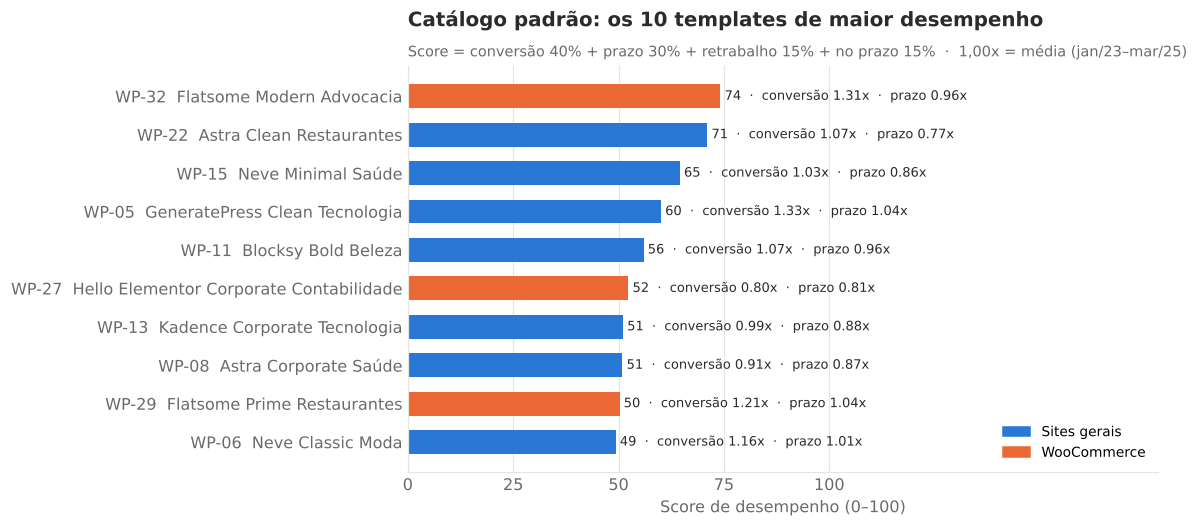

In [10]:
G.ranking_top10(top);

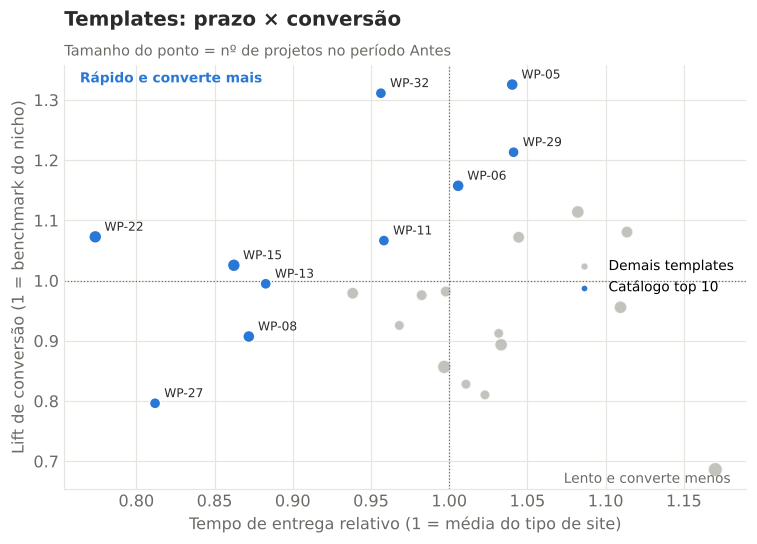

In [11]:
G.quadrante_templates(rank);

**Regra de negócio:** o catálogo precisa ter pelo menos 3 templates de cada família (sites gerais e WooCommerce).
Por isso o WP-27 entrou mesmo com conversão abaixo da média: ele é o WooCommerce mais rápido e com menos retrabalho.

## 5. Classificação por nicho × tipo de site
O resultado prático para a equipe é uma matriz que indica qual template usar em cada projeto.

In [12]:
rec = A.matriz_recomendacao(top)
rec.pivot(index="nicho", columns="tipo_site", values="template_id")

tipo_site,Blog / Portal,Catálogo de Produtos,Institucional,Landing Page,Loja Virtual (WooCommerce),Portfólio
nicho,,,,,,
Academias e Fitness,WP-22,WP-32,WP-22,WP-22,WP-32,WP-22
Advocacia,WP-22,WP-32,WP-22,WP-22,WP-32,WP-22
Beleza e Estética,WP-11,WP-32,WP-11,WP-11,WP-32,WP-11
Contabilidade,WP-22,WP-27,WP-22,WP-22,WP-27,WP-22
Educação e Cursos,WP-22,WP-32,WP-22,WP-22,WP-32,WP-22
Imobiliárias,WP-22,WP-32,WP-22,WP-22,WP-32,WP-22
Moda e Varejo,WP-06,WP-32,WP-06,WP-06,WP-32,WP-06
Restaurantes e Delivery,WP-22,WP-29,WP-22,WP-22,WP-29,WP-22
Saúde e Clínicas,WP-15,WP-32,WP-15,WP-15,WP-32,WP-15


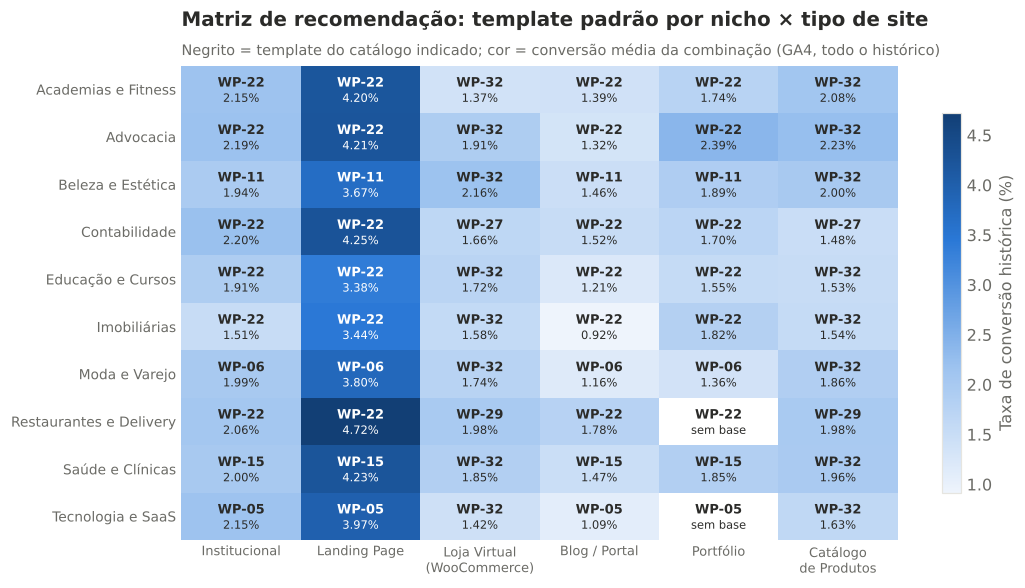

In [13]:
G.matriz_nicho_tipo(proj, rec);

## 6. Teste piloto de 30 dias (01 a 30/jun/2025)
Antes de mudar o processo de toda a equipe, a proposta foi testada por 30 dias em duas frentes:
- **Teste A/B de conversão:** 12 sites publicados, com as páginas principais em duas versões (A = layout atual, B = template do catálogo) e tráfego 50/50, medido no GA4.
- **Projetos Teste × Controle:** projetos iniciados no mês, alternados entre escolha livre (Controle) e catálogo + fluxo (Teste).

O resultado foi apresentado no dashboard `excel/dashboard_teste_piloto_30_dias.xlsx`.

In [14]:
ab_res, ab_teste, ab_diario = A.piloto_ab()
display(ab_res)
print(f"Conversão A = {ab_teste['taxa_A']:.2%} | B = {ab_teste['taxa_B']:.2%} | lift = {ab_teste['lift']:+.1%}")
print(f"z = {ab_teste['z']:.2f} | p-valor = {ab_teste['p_valor']:.3f} | IC 95% da diferença = "
      f"[{ab_teste['ic95_dif_pp'][0]:+.2f}, {ab_teste['ic95_dif_pp'][1]:+.2f}] p.p.")

,descricao_variante,sites,dias,sessoes,conversoes,taxa_conversao_pct,taxa_engajamento_pct
variante,,,,,,,
A,Layout atual,12,30,43232,859,1.987,54.7
B,Template do catálogo,12,30,43365,960,2.214,58.1


Conversão A = 1.99% | B = 2.21% | lift = +11.4%
z = 2.33 | p-valor = 0.010 | IC 95% da diferença = [+0.04, +0.42] p.p.


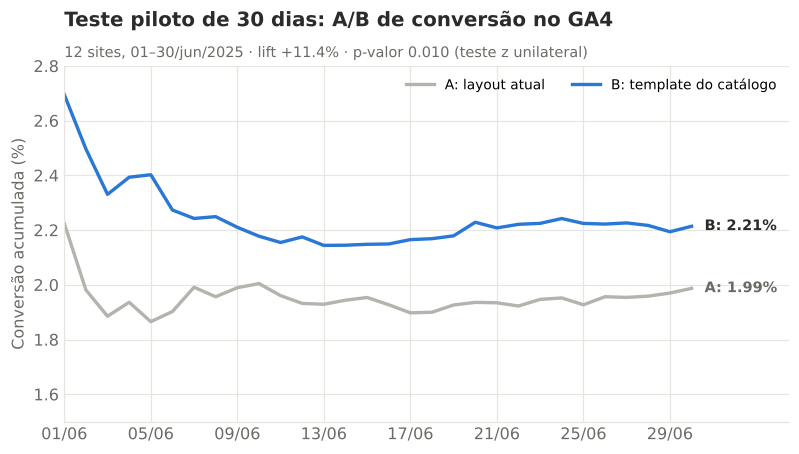

In [15]:
G.piloto_ab_acumulado(ab_diario, ab_teste);

In [16]:
A.piloto_projetos()

,projetos,dias_medios_entrega,retrabalho_medio,dias_escolha_layout,dias_design_aprovacao
grupo_piloto,,,,,
Controle,7,44.6,0.86,9.4,6.4
Teste,6,30.2,0.17,1.8,5.2


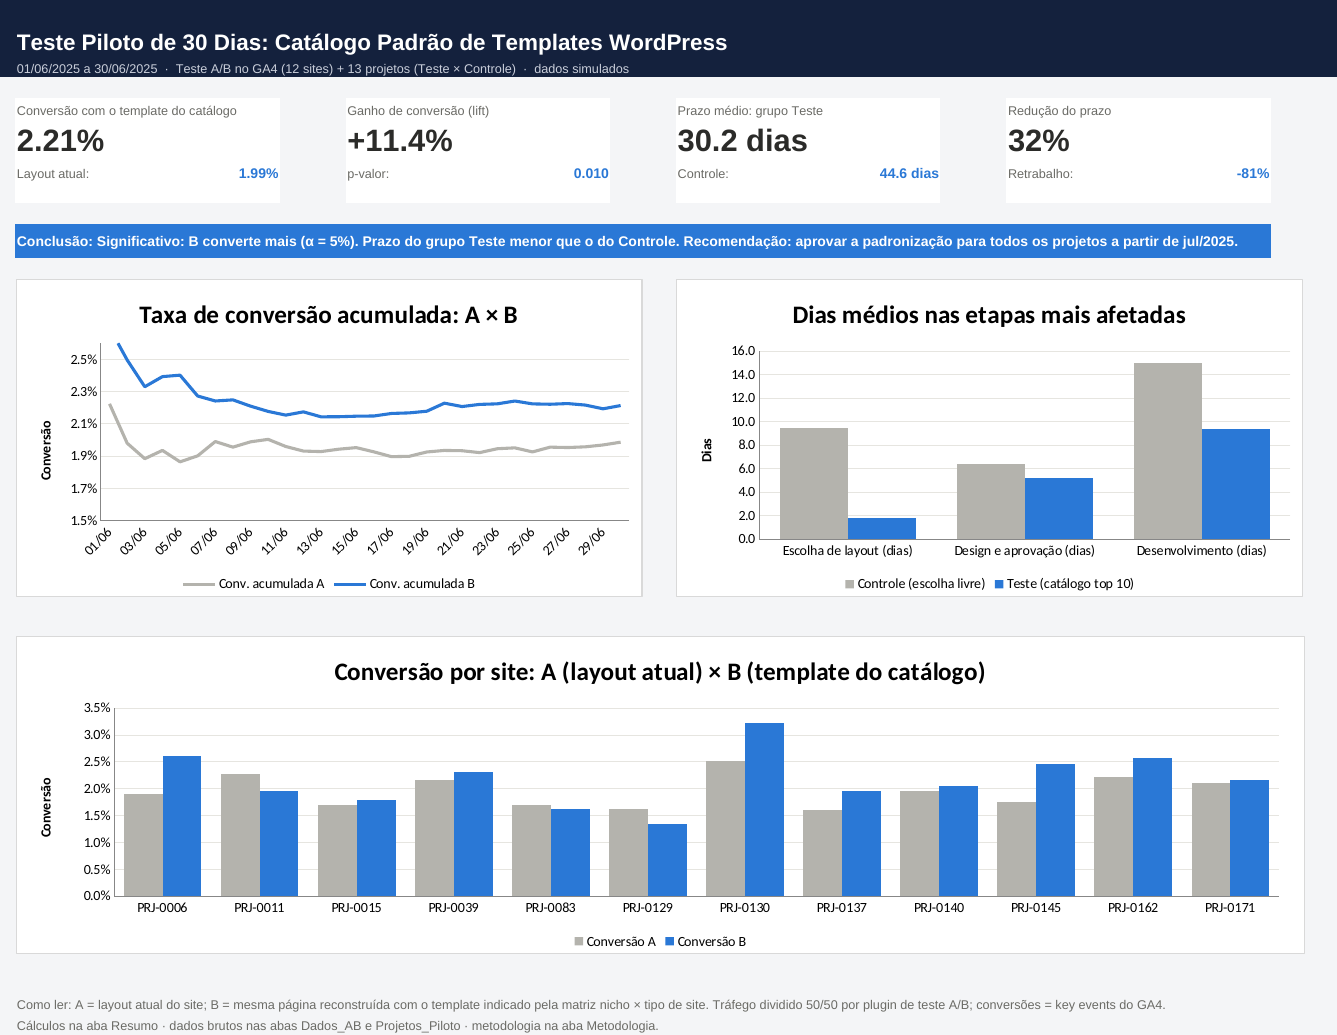

In [17]:
display(Image(filename=str(RAIZ / "excel/preview_dashboard_excel.png"), width=900))

**Leitura:** o A/B mostrou conversão **11% maior** com o template do catálogo, com significância estatística (p ≈ 0,01).
No grupo Teste, a escolha de layout caiu de 9,4 para 1,8 dia e o prazo total caiu 32%. Com apenas 13 projetos, esse efeito no prazo foi tratado
como **indicativo**. **Decisão da gestão:** aprovar o rollout em 01/07/2025 e acompanhar no Power BI.

## 7. Resultado do rollout: antes × depois

In [18]:
resumo, var = A.antes_depois(proj)
display(resumo)
var.map("{:+.1%}".format).to_frame()

,projetos,dias_medios_entrega,pct_no_prazo,retrabalho_medio,sessoes,conversoes,taxa_conversao_pct
periodo,,,,,,,
Antes,195,44.8,25.6,1.50,1144969,23018,2.01
Depois,137,31.5,69.3,0.61,567013,12566,2.22


,variação
dias_medios_entrega,-29.7%
taxa_conversao_pct,+10.4%
pct_no_prazo,+43.7%
retrabalho_medio,-59.3%


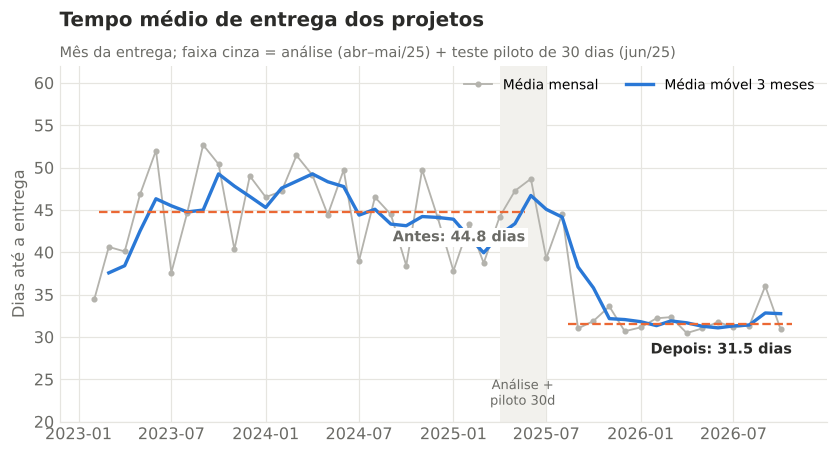

In [19]:
G.evolucao_prazo(proj);

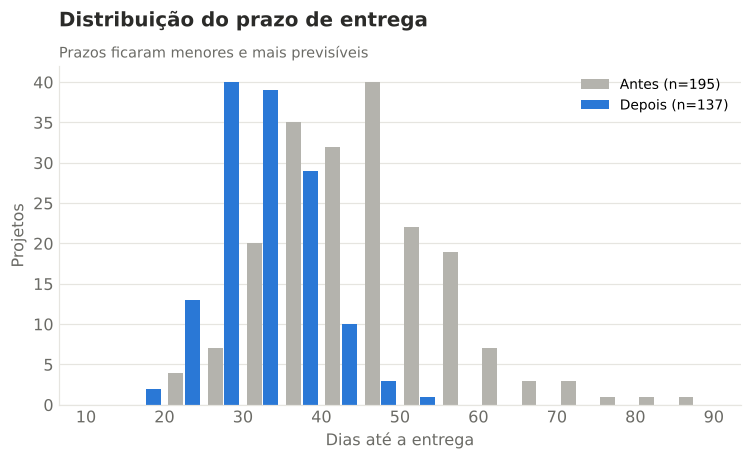

In [20]:
G.distribuicao_prazo(proj);

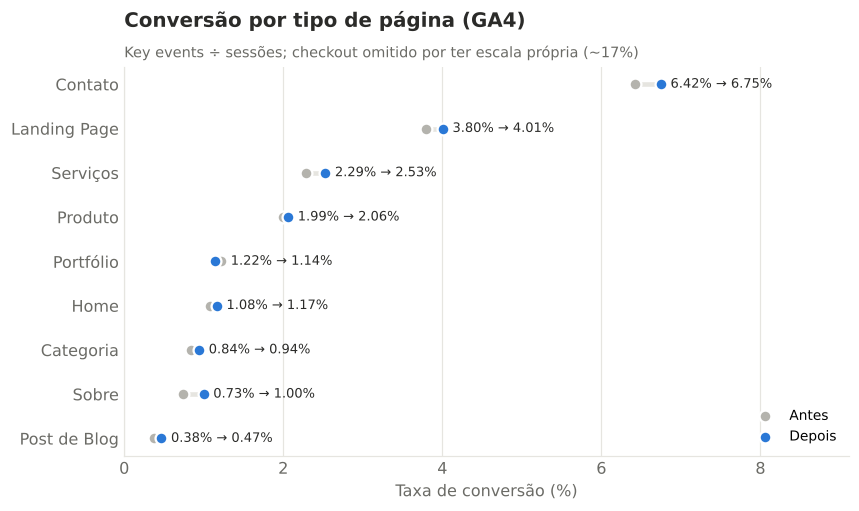

In [21]:
G.conversao_por_pagina(ga);

### Teste estatístico
Prazo: Mann-Whitney (unilateral). Conversão: *bootstrap* por projeto, já que as sessões de um mesmo site não são independentes.

In [22]:
t = A.testes_estatisticos(proj)
print(f"Prazo  -> p-valor = {t['p_valor_prazo']:.1e}")
print(f"Conversão -> lift = {t['lift_conversao']:+.1%} | IC 95% = [{t['ic95_lift'][0]:+.1%}, {t['ic95_lift'][1]:+.1%}] | P(lift > 0) = {t['prob_lift_positivo']:.0%}")

Prazo  -> p-valor = 1.8e-29
Conversão -> lift = +10.2% | IC 95% = [-0.4%, +22.7%] | P(lift > 0) = 97%


**Leitura honesta:**
- A redução do prazo é **robusta**: p-valor perto de zero, e a distribuição inteira se deslocou para prazos menores.
- O ganho de conversão (+10%, de 2,0% para 2,2%) é **provável, mas ainda incerto**: o intervalo de confiança encosta no zero.
  O A/B controlado do piloto (p ≈ 0,01) reforça que o efeito é real. A recomendação é continuar acompanhando no Power BI.

## 8. Conclusões

| Indicador | Antes | Depois | Variação |
|---|---|---|---|
| Tempo médio de entrega | 44,8 dias | 31,5 dias | **−30%** |
| Taxa de conversão (GA4) | 2,01% | 2,22% | **+10%** |
| Entregas no prazo | 26% | 69% | +44 p.p. |
| Rodadas de retrabalho | 1,50 | 0,61 | −59% |

1. O gargalo estava na **escolha do layout e no ciclo de aprovação**, não no desenvolvimento em si.
2. Templates leves (Gutenberg/Elementor) com nicho-alvo definido entregam mais rápido e convertem mais.
3. O teste piloto de 30 dias (A/B + Teste × Controle) validou a proposta antes do rollout, e o resultado foi apresentado em dashboard Excel.
4. Um catálogo de 10 templates com matriz nicho × tipo eliminou a escolha subjetiva e reduziu o retrabalho.
5. Próximos passos: revisão trimestral do ranking, novos A/B entre templates do catálogo e inclusão de Core Web Vitals no score.